In [137]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

# Reading and Exploring the features

- handling duplicates and nulls 
- converting some `str` columns into numerical ones [`PostedDate`, `AskPrice`, `kmDriven`]

In [138]:
used_cars_df = pd.read_csv('../used-car-dataset/used_cars_dataset_v2.csv')
used_cars_df 

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001,23,"98,000 km",Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,Innova,2009,15,190000.0 km,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,VentoTest,2010,14,"77,246 km",Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,Maruti Suzuki,Swift,2017,7,"83,500 km",Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,Baleno,2019,5,"45,000 km",Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"
...,...,...,...,...,...,...,...,...,...,...,...
14988,Maruti Suzuki,Wagon-R,2022,2,"31,000 km",Manual,first,hybrid,Nov-24,"Maruti Suzuki Wagon R LXI CNG Optional, 2022, ...","₹ 5,75,000"
14989,BMW,X1,2017,7,"45,000 km",Automatic,second,Diesel,Dec-24,"BMW X1 2.0 SDRIVE 20D, 2017, Diesel","₹ 13,45,000"
14990,Maruti Suzuki,New-gen Swift,2011,13,"60,000 km",Automatic,second,Diesel,Nov-24,Bahut badhiya new condition,"₹ 1,60,000"
14991,Tata,Zest,2019,5,"62,000 km",Manual,second,hybrid,Nov-24,"Tata Zest Revotron 1.2T XE, 2019, CNG & Hybrids","₹ 3,80,000"


In [139]:
used_cars_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14993 entries, 0 to 14992
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Brand         14993 non-null  str  
 1   model         14993 non-null  str  
 2   Year          14993 non-null  int64
 3   Age           14993 non-null  int64
 4   kmDriven      14905 non-null  str  
 5   Transmission  14993 non-null  str  
 6   Owner         14993 non-null  str  
 7   FuelType      14993 non-null  str  
 8   PostedDate    14993 non-null  str  
 9   AdditionInfo  14993 non-null  str  
 10  AskPrice      14993 non-null  str  
dtypes: int64(2), str(9)
memory usage: 1.3 MB


In [140]:
used_cars_df.isna().mean() * 100

Brand           0.000000
model           0.000000
Year            0.000000
Age             0.000000
kmDriven        0.586941
Transmission    0.000000
Owner           0.000000
FuelType        0.000000
PostedDate      0.000000
AdditionInfo    0.000000
AskPrice        0.000000
dtype: float64

In [141]:
print("Count of duplicates :", used_cars_df.duplicated().sum())
print(f'Percentage of duplicates : {used_cars_df.duplicated().mean()*100:.2f}%')

Count of duplicates : 997
Percentage of duplicates : 6.65%


In [142]:
used_cars_df.drop_duplicates(inplace=True)
used_cars_df.dropna(inplace=True)

In [143]:
used_cars_df.isna().sum()

Brand           0
model           0
Year            0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
PostedDate      0
AdditionInfo    0
AskPrice        0
dtype: int64

In [144]:
val_unit_kmDriven = used_cars_df['kmDriven'].str.split()
val_unit_kmDriven.str[1].value_counts()

kmDriven
km    13909
Name: count, dtype: int64

In [145]:
currency_price_AskPrice = used_cars_df['AskPrice'].str.split()
currency_price_AskPrice.str[0].value_counts()

AskPrice
₹    13909
Name: count, dtype: int64

In [146]:
used_cars_df['kmDriven'] = used_cars_df['kmDriven'].str.replace(r'[^\d.]', '',regex=True).astype(float)
used_cars_df['AskPrice'] = used_cars_df['AskPrice'].str.replace(r'[^\d.]', '', regex=True).astype(float)

In [147]:
used_cars_df['postedMonth'] = used_cars_df['PostedDate'].str.replace(r'[\d-]', '', regex=True)
used_cars_df['postedYear'] = used_cars_df['PostedDate'].str.replace(r'[\D]', '', regex=True).astype(int)
used_cars_df['postedYear'] = used_cars_df['postedYear'] + 2000


In [148]:
month_format = used_cars_df['postedMonth'].value_counts().index.tolist()
month_format

['Nov',
 'Dec',
 'Oct',
 'Sep',
 'Aug',
 'Jul',
 'Jun',
 'Apr',
 'May',
 'Jan',
 'Feb',
 'Mar']

In [149]:
month_format = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep','Oct', 'Nov','Dec']
dict={}

for i in range(len(month_format)):
    dict[month_format[i]] = i+1

used_cars_df['postedMonth'] = used_cars_df['postedMonth'].map(dict)


In [150]:
used_cars_df[['PostedDate','postedMonth','postedYear']]

,PostedDate,postedMonth,postedYear
0,Nov-24,11,2024
1,Jul-24,7,2024
2,Nov-24,11,2024
3,Nov-24,11,2024
4,Nov-24,11,2024
...,...,...,...
14988,Nov-24,11,2024
14989,Dec-24,12,2024
14990,Nov-24,11,2024
14991,Nov-24,11,2024


In [151]:
used_cars_df[['kmDriven', 'AskPrice']]

,kmDriven,AskPrice
0,98000.0,195000.0
1,190000.0,375000.0
2,77246.0,184999.0
3,83500.0,565000.0
4,45000.0,685000.0
...,...,...
14988,31000.0,575000.0
14989,45000.0,1345000.0
14990,60000.0,160000.0
14991,62000.0,380000.0


In [152]:
used_cars_df.info()

<class 'pandas.DataFrame'>
Index: 13909 entries, 0 to 14992
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         13909 non-null  str    
 1   model         13909 non-null  str    
 2   Year          13909 non-null  int64  
 3   Age           13909 non-null  int64  
 4   kmDriven      13909 non-null  float64
 5   Transmission  13909 non-null  str    
 6   Owner         13909 non-null  str    
 7   FuelType      13909 non-null  str    
 8   PostedDate    13909 non-null  str    
 9   AdditionInfo  13909 non-null  str    
 10  AskPrice      13909 non-null  float64
 11  postedMonth   13909 non-null  int64  
 12  postedYear    13909 non-null  int64  
dtypes: float64(2), int64(4), str(7)
memory usage: 1.5 MB


In [153]:
used_cars_df[['Brand', 'model', 'Year', 'AdditionInfo']]

,Brand,model,Year,AdditionInfo
0,Honda,City,2001,"Honda City v teck in mint condition, valid gen..."
1,Toyota,Innova,2009,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D..."
2,Volkswagen,VentoTest,2010,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010..."
3,Maruti Suzuki,Swift,2017,Maruti Suzuki Swift 2017 Diesel Good Condition
4,Maruti Suzuki,Baleno,2019,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol"
...,...,...,...,...
14988,Maruti Suzuki,Wagon-R,2022,"Maruti Suzuki Wagon R LXI CNG Optional, 2022, ..."
14989,BMW,X1,2017,"BMW X1 2.0 SDRIVE 20D, 2017, Diesel"
14990,Maruti Suzuki,New-gen Swift,2011,Bahut badhiya new condition
14991,Tata,Zest,2019,"Tata Zest Revotron 1.2T XE, 2019, CNG & Hybrids"


In [154]:
def extract_info(d):
    t = d["AdditionInfo"].fillna("").str.lower()
    t_nofuel = t.str.replace(r"cng & hy\w*\.*", "", regex=True)  # drop scraped suffix
    out = pd.DataFrame(index=d.index)
    out["engine_l"]  = t.str.extract(r"(?<![\d.])(\d\.\d{1,2})(?!\d)(?!\s*(?:marla|lakh|lac))")[0].astype(float)
    out["seats"]     = t.str.extract(r"(\d)[\s-]*(?:seater|seats?|str)\b")[0].astype(float)
    out["is_4wd"]    = t.str.contains(r"4\s?x\s?4|4wd|\bawd\b|xdrive|4matic|quattro|4motion").astype(int)
    out["cng_in_text"] = t_nofuel.str.contains(r"\bcng\b").astype(int)
    out["is_top"]    = t.str.contains(r"top[\s-]*(?:model|end|variant|varient)|fully loaded|full option").astype(int)
    out["well_kept"] = t.str.contains(r"well[\s-]*(?:maintained|kept)|\bmint\b|good condition|excellent|like new").astype(int)
    return out


df_copy = used_cars_df.copy()
df_copy = df_copy.join(extract_info(used_cars_df))
df_copy

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice,postedMonth,postedYear,engine_l,seats,is_4wd,cng_in_text,is_top,well_kept
0,Honda,City,2001,23,98000.0,Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...",195000.0,11,2024,NaN,NaN,0,0,0,1
1,Toyota,Innova,2009,15,190000.0,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000.0,7,2024,2.5,7.0,0,0,0,0
2,Volkswagen,VentoTest,2010,14,77246.0,Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0,11,2024,NaN,NaN,0,0,0,0
3,Maruti Suzuki,Swift,2017,7,83500.0,Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,565000.0,11,2024,NaN,NaN,0,0,0,1
4,Maruti Suzuki,Baleno,2019,5,45000.0,Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000.0,11,2024,NaN,NaN,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14988,Maruti Suzuki,Wagon-R,2022,2,31000.0,Manual,first,hybrid,Nov-24,"Maruti Suzuki Wagon R LXI CNG Optional, 2022, ...",575000.0,11,2024,NaN,NaN,0,1,0,0
14989,BMW,X1,2017,7,45000.0,Automatic,second,Diesel,Dec-24,"BMW X1 2.0 SDRIVE 20D, 2017, Diesel",1345000.0,12,2024,2.0,NaN,0,0,0,0
14990,Maruti Suzuki,New-gen Swift,2011,13,60000.0,Automatic,second,Diesel,Nov-24,Bahut badhiya new condition,160000.0,11,2024,NaN,NaN,0,0,0,0
14991,Tata,Zest,2019,5,62000.0,Manual,second,hybrid,Nov-24,"Tata Zest Revotron 1.2T XE, 2019, CNG & Hybrids",380000.0,11,2024,1.2,NaN,0,0,0,0


In [155]:
df_copy.isna().mean()*100

Brand            0.000000
model            0.000000
Year             0.000000
Age              0.000000
kmDriven         0.000000
Transmission     0.000000
Owner            0.000000
FuelType         0.000000
PostedDate       0.000000
AdditionInfo     0.000000
AskPrice         0.000000
postedMonth      0.000000
postedYear       0.000000
engine_l        64.950751
seats           96.635272
is_4wd           0.000000
cng_in_text      0.000000
is_top           0.000000
well_kept        0.000000
dtype: float64

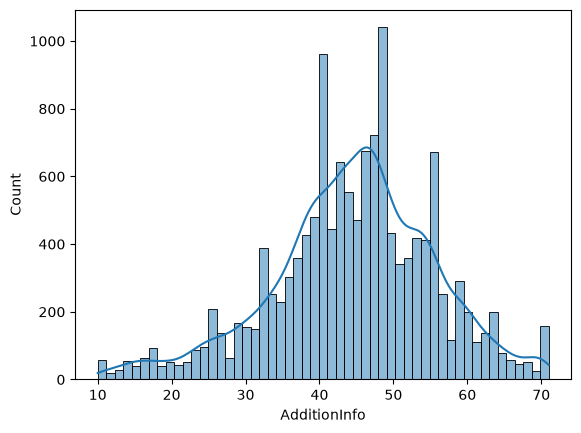

In [164]:
plt.subplots()
sns.histplot(data=pd.DataFrame(used_cars_df['AdditionInfo'].str.len()), x='AdditionInfo', kde=True)
plt.show()

# Explortary Data Analysis **EDA** 